# De la probabilité à une mesure

Le critère tient en une phrase : parmi les paquets dont la probabilité de dépasser 1 500 hospitalisés ou 300 soins intensifs reste d'au plus 5 %, on prend celui dont le coût cumulé est le plus bas.

Deux règles d'effet, différentes de la règle de coût.

- Les coûts du jour s'additionnent. Masque (1) plus isolement (2) coûte 3 ce jour-là.
- Les réductions de contacts ne s'additionnent pas. C'est la plus forte qui s'applique. Le masque, lui, multiplie ensuite le taux d'infection (environ −20 %, fois le respect de 90 %).
- L'isolement des cas et la quarantaine du ménage ne vont pas ensemble.

Une seule trajectoire déterministe ne donne pas cette probabilité. Elle montre seulement le sens des mesures. La probabilité vient des tirages a posteriori, projetés sous chaque paquet. La fin du notebook sépare les deux.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Le notebook est dans notebooks/. On remonte à la racine du dépôt.
RACINE = Path.cwd().resolve()
if not (RACINE / "pyproject.toml").exists():
    RACINE = RACINE.parent
sys.path.insert(0, str(RACINE / "src"))

%matplotlib inline
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.max_colwidth", 80)


## Le menu, palier par palier


In [2]:
from epidemic.config import load_decision_config, load_game_config, load_scenarios_config
from epidemic.decision.catalog import enumerate_scenarios
from epidemic.simulator.interventions import LABELS, assert_compatible

jeu = load_game_config()
scenarios = load_scenarios_config()
decision = load_decision_config()

print(f"Seuil de saturation : {decision.alpha:.0%}")
print(f"Délai de mise en œuvre : {jeu.implementation_delay_days} jours")
print(f"Durée minimale d'une mesure : {jeu.min_policy_days} jours")
print()
for palier in jeu.tiers:
    print(f"Palier {palier.level}, à partir du jour {palier.from_day}")
    if not palier.interventions:
        print("  aucune mesure")
        continue
    for nom in palier.interventions:
        print(f"  {LABELS[nom]}")


Seuil de saturation : 5%
Délai de mise en œuvre : 3 jours
Durée minimale d'une mesure : 14 jours

Palier 0, à partir du jour 1
  aucune mesure
Palier 1, à partir du jour 21
  Masque
  Isolement des cas
Palier 2, à partir du jour 42
  Masque
  Isolement des cas
  Quarantaine du ménage
  Distanciation sociale
Palier 3, à partir du jour 63
  Masque
  Isolement des cas
  Quarantaine du ménage
  Distanciation sociale
  Confinement


In [3]:
try:
    assert_compatible(["case_isolation", "household_quarantine"], scenarios)
except ValueError as erreur:
    print(erreur)

def palier_de(niveau: int):
    """Retrouve le palier par son numéro, pas par sa place dans la liste."""
    return next(item for item in jeu.tiers if item.level == niveau)

for niveau in (1, 3):
    palier = palier_de(niveau)
    paquets = enumerate_scenarios(list(palier.interventions), scenarios, decision)
    print(f"Palier {niveau} : {len(paquets)} paquets, durées et âges compris")

palier_1 = enumerate_scenarios(list(palier_de(1).interventions), scenarios, decision)
print()
print("Palier 1, libellés :")
for paquet in palier_1:
    print(f"  {paquet.label}")


Isolement des cas incompatible avec Quarantaine du ménage.
Palier 1 : 8 paquets, durées et âges compris
Palier 3 : 112 paquets, durées et âges compris

Palier 1, libellés :
  Aucune mesure
  Masque
  Isolement des cas 7 j
  Isolement des cas 10 j
  Isolement des cas 14 j
  Masque + Isolement des cas 7 j
  Masque + Isolement des cas 10 j
  Masque + Isolement des cas 14 j


`enumerate_scenarios` développe la grille de `configs/decision.yaml` : isolement ou quarantaine sur 7, 10 ou 14 jours, distanciation à partir de 50, 60 ou 70 ans. Le palier 3 en a donc beaucoup plus que cinq. Le palier 1 n'a pas de paramètre d'âge, seulement la durée d'isolement.


## Ce que fait une mesure sur une ville déterministe

Pour que la vague soit lisible en 80 jours, on relève β et le nombre d'exposés initiaux, et on éteint le fond grippal. Le niveau 0 retire le tirage binomial : la courbe est le chemin moyen de cette ville-là.

Les mesures partent le jour 1. Dans le jeu, ce n'est pas le cas : le confinement n'est même pas proposé avant le jour 63, et toute décision attend 3 jours. Le graphique répond à une question plus étroite : à paramètres fixés, réduire les contacts réduit-il les lits ?


In [4]:
from dataclasses import replace

from epidemic.simulator import RealitySimulator
from epidemic.simulator.interventions import AppliedPolicy

graine = 0
depart = RealitySimulator.from_configs(seed=graine, level=0).truth
verite = replace(
    depart,
    beta_per_contact=0.05,
    initial_exposed=120,
    incubation_days=2.0,
    presymptomatic_days=1.5,
    symptomatic_days=6.0,
    asymptomatic_days=6.0,
    symptomatic_fraction=0.6,
    flu_daily_mean=0.0,
)

def simuler(mesures: list[AppliedPolicy]) -> pd.DataFrame:
    """Rejoue la même ville, avec un paquet tenu pendant 80 jours."""
    ville = RealitySimulator.from_configs(seed=graine, level=0, truth=verite)
    observations, _cache = ville.run(80, policies=mesures)
    return observations

chemins = {
    "Aucune mesure": simuler([]),
    "Masque": simuler([AppliedPolicy("mask")]),
    "Confinement": simuler([AppliedPolicy("lockdown")]),
}
for nom, frame in chemins.items():
    print(
        f"{nom:16} pic d'hospitalisés {int(frame['num_hospitalised'].max()):5d}"
        f"   pic de soins intensifs {int(frame['num_critical'].max()):4d}"
    )


Aucune mesure    pic d'hospitalisés  4172   pic de soins intensifs  450
Masque           pic d'hospitalisés  1315   pic de soins intensifs  113
Confinement      pic d'hospitalisés     0   pic de soins intensifs    0


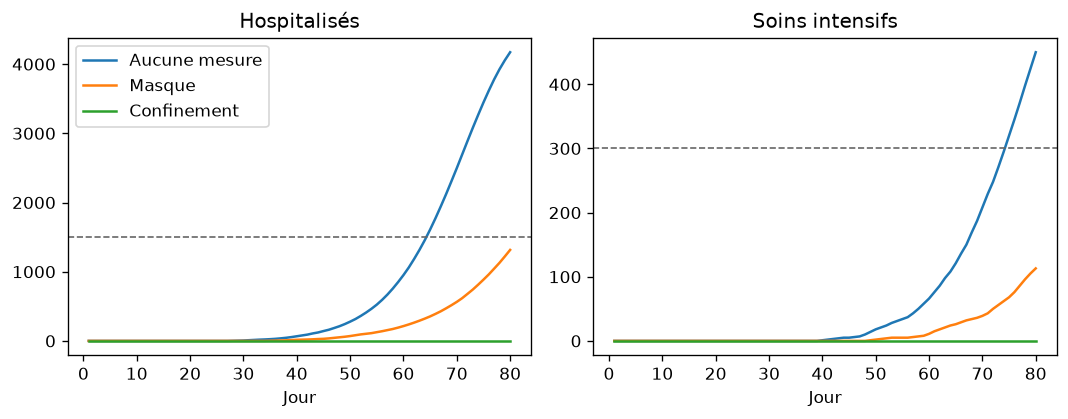

In [5]:
from epidemic.config import load_thresholds_config

plafonds = load_thresholds_config()
figure, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
for nom, frame in chemins.items():
    axes[0].plot(frame["Day"], frame["num_hospitalised"], label=nom)
    axes[1].plot(frame["Day"], frame["num_critical"], label=nom)
axes[0].axhline(plafonds.max_hospitalized, color="0.4", linestyle="--", linewidth=1)
axes[1].axhline(plafonds.max_critical, color="0.4", linestyle="--", linewidth=1)
axes[0].set_title("Hospitalisés")
axes[1].set_title("Soins intensifs")
axes[0].set_xlabel("Jour")
axes[1].set_xlabel("Jour")
axes[0].legend()
figure.tight_layout()


Sur cette ville précise, le masque reste sous les deux traits pointillés, et le confinement écrase la vague. Le masque est moins coûteux. Une décision qui ne regarderait que ce chemin choisirait le masque.

Ce n'est pas encore la règle du projet. β, la gravité et le dépistage sont incertains, et l'avenir reste aléatoire. Une autre valeur de β peut faire franchir 1 500 au masque. Il faut la probabilité de ce franchissement, pas le pic d'un seul scénario.


## La règle, sur quatre options fictives

Les probabilités ci-dessous sont choisies pour la démonstration. Elles ne sortent pas d'un ajustement. `recommend` retient le coût le plus bas parmi les options sous le seuil. Si aucune n'y est, elle ne choisit pas : elle signale la plus sûre, et le champ `chosen` reste vide.


In [6]:
import numpy as np

from epidemic.decision.recommend import recommend
from epidemic.decision.recommend import ScoredOption

def option_jouet(cle: str, libelle: str, cout: float, proba: float) -> ScoredOption:
    """Option fictive : seul le coût et P(saturation) comptent pour la règle."""
    return ScoredOption(
        key=cle,
        label=libelle,
        kind="scenario",
        unit_cost=cout,
        expected_cost=cout,
        factor=1.0,
        p_hospital=proba,
        p_critical=proba,
        p_saturation=proba,
        deaths_median=0.0,
        deaths_low=0.0,
        deaths_high=0.0,
        peak_hospital_median=0.0,
        peak_hospital_day=0.0,
        peak_critical_median=0.0,
        peak_critical_day=0.0,
        days_saturated_median=0.0,
        p_rt_now=0.0,
        p_rt_end=0.0,
        first_day=np.array([]),
        weekly_rt_below=np.array([]),
        fans={},
    )

options = [
    option_jouet("aucune", "Aucune mesure", cout=0, proba=0.40),
    option_jouet("masque", "Masque", cout=40, proba=0.08),
    option_jouet("masque_isolement", "Masque + isolement 10 j", cout=90, proba=0.04),
    option_jouet("confinement", "Confinement", cout=200, proba=0.01),
]
choix = recommend(options, alpha=0.05)
print(choix.message)
print("Retenu :", None if choix.chosen is None else choix.chosen.label)
print("Sous le seuil :", [option.label for option in choix.feasible])

trop_tard = [
    option_jouet("aucune", "Aucune mesure", cout=0, proba=0.50),
    option_jouet("masque", "Masque", cout=40, proba=0.20),
    option_jouet("confinement", "Confinement", cout=200, proba=0.12),
]
refus = recommend(trop_tard, alpha=0.05)
print()
print(refus.message)
print("Retenu :", refus.chosen)


Masque + isolement 10 j : coût cumulé 90, probabilité de saturation 4%.
Retenu : Masque + isolement 10 j
Sous le seuil : ['Masque + isolement 10 j', 'Confinement']

Toutes les options dépassent le seuil de 5% de saturation. La plus sûre est « Confinement », avec une probabilité de 12%.
Retenu : None


Dans le premier cas, le masque est à 8 %, au-dessus de 5 %. Il est écarté, même s'il coûte moins cher que l'isolement. Le confinement est sous le seuil, mais plus cher. Le paquet retenu est le masque avec isolement.

Dans le second cas, tout dépasse 5 %. La fonction ne fait pas semblant de choisir. Elle désigne le confinement comme issue la plus sûre, sans le recommander au sens du seuil.

Le calcul réel suit le même classement, avec des probabilités issues des tirages :

1. `fit_observations` produit la loi a posteriori ;
2. `project_scenarios` prolonge chaque tirage sous la matrice de contact du paquet ;
3. `prepare_bulletin` en fait des `ScoredOption` (coût cumulé, pics, P(saturation)) ;
4. `recommend` applique la règle ci-dessus.

Pendant le délai de mise en œuvre, la politique déjà en cours continue de coûter. Ensuite, c'est le paquet choisi. Le bulletin qui écrit cela en deux pages est `uv run epidemic bulletin --day 21`. Sans fichier de loi a posteriori, il le dit et retombe sur une référence naïve, plutôt que d'inventer une probabilité.
